## Algorithm 1 : Forward , Backward ,Forward

The goal of this notebook is to implrement the optimization algorithm Forward , Backward  , Forward , we will try to visualise the graphs resulting from the optimization on some toy examples.

In [1]:
import numpy as np

# Helper Functions

In [2]:
def conv_indicator(w):
    if w >= 0:
       return 0
    else :
       return np.inf

In [3]:
def Z_matrix(signals):
    # signals is (m,n) array denoted as (x_{i,j})_{i,j} in the paper
    m,n =signals.shape()
    Z = ((signals[:,None,:]- signals[None ,:,:])**2).sum(-1)
    mask = np.arange(m) > np.arange(m)
    return Z[mask]

In [4]:
def S(m):
    S= np.zeros((m*(m-1)/2 , m*(m-1)*2))
    i=0; j=0
    while i<m*(m-1)/2 : 
        for t in range((i-1)*(i-2)*2,i*(i-1)*2):
            if t>=0 :
               S[i,t]=1
        j=i*(i-1)/2    
        k=0

        while j+ k*(k-1)/2 <= m*(m-1)/2:
            S[i,j+k*(k-1)/2]=1
            k+=1

        i+=1

    return S

In [5]:
max_iter =10e2

In [6]:
def Primal_dual_algo(z,alpha,beta,w0,d0,gamma,epsilon,m):
    wi=w0
    di =d0
    S=S(m)
    for i in range(max_iter):

        yi= wi - gamma*(2*beta*wi + S.T @ di)    

        y_bar_i = di +gamma* S@wi
        
        pi = np.max(0, yi-2*gamma*z)
        
        p_bar_i= (yi -np.sqrt(y_bar_i**2+4*alpha*gamma))/2
        
        qi=pi-gamma*(2*beta*pi+ S.T@pi)
        
        q_bar_i = p_bar_i + gamma * S@pi




        w_i1=wi
        d_i1=di
        wi=wi-yi+pi
        di=di-y_bar_i+p_bar_i
        if np.norm(wi-w_i1 )/np.norm(wi)<epsilon and np.norm(di-d_i1 )/np.norm(di)<epsilon : break





    return wi , di

## Experiments and visualisations

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.sparse.csgraph import connected_components


def Z_vec(signals):
    """signals: (m, n) with m NODES as rows, n samples as columns.
    Returns z of shape (m(m-1)/2,) holding ||x_i - x_j||^2 for i < j, plus the index arrays."""
    m = signals.shape[0]                                   # .shape is an attribute, not a call
    Z = ((signals[:, None, :] - signals[None, :, :])**2).sum(-1)
    i, j = np.triu_indices(m, k=1)                         # k=1: strictly upper, no diagonal
    return Z[i, j], i, j


def S_op(m):
    """Edge -> node operator, shape (m, m(m-1)/2), such that (S @ w)[i] = degree of node i."""
    i, j = np.triu_indices(m, k=1)
    E = len(i)
    S = np.zeros((m, E))
    e = np.arange(E)
    S[i, e] = 1.0
    S[j, e] = 1.0
    return S


def vec_to_W(w, m):
    """Edge vector -> symmetric adjacency matrix (same triu ordering as Z_vec / S_op)."""
    i, j = np.triu_indices(m, k=1)
    W = np.zeros((m, m))
    W[i, j] = w
    return W + W.T


def fbf_primal_dual(z, alpha, beta, S, max_iter=100000, eps=1e-10):
    """Algorithm 1 (primal-dual forward-backward-forward) for model (15):

           min_{w >= 0}  2 z^T w  -  alpha * sum_i log((S w)_i)  +  beta * ||w||^2

       f1(w) = i{w>=0} + 2 w^T z     -> prox  : max(0, y - 2*gamma*z)
       f2(d) = -alpha * 1^T log(d)   -> prox* : (yb - sqrt(yb^2 + 4*alpha*gamma))/2
       f3(w) = beta ||w||^2          -> grad  : 2*beta*w,  Lipschitz zeta = 2*beta

    Returns (w, d, n_iter).  Note d is the DUAL variable: it converges to -alpha/degree,
    so it is negative; the degrees themselves are S @ w.
    """
    m, E = S.shape
    gamma = 0.9 / (2.0*beta + np.linalg.norm(S, 2))        # condition (6): gamma < 1/(zeta+||S||)
    w = np.zeros(E)
    d = np.zeros(m)

    for it in range(max_iter):
        y   = w - gamma*(2*beta*w + S.T @ d)                   # 2: primal forward
        y_b = d + gamma*(S @ w)                                # 3: dual forward
        p   = np.maximum(0.0, y - 2*gamma*z)                   # 4: prox_{gamma f1}, entrywise
        p_b = (y_b - np.sqrt(y_b**2 + 4*alpha*gamma)) / 2.0    # 5: prox_{gamma f2*}, entrywise
        q   = p   - gamma*(2*beta*p + S.T @ p_b)               # 6: correction (forward) step
        q_b = p_b + gamma*(S @ p)                              # 7
        w_new = w - y   + q                                    # 8: primal update
        d_new = d - y_b + q_b                                  # 9: dual update

        # guard the relative test against the w = 0, d = 0 start
        if it > 1 and np.linalg.norm(w_new - w) <= eps*max(np.linalg.norm(w), 1e-12) \
                  and np.linalg.norm(d_new - d) <= eps*max(np.linalg.norm(d), 1e-12):
            return w_new, d_new, it + 1
        w, d = w_new, d_new

    print("warning: hit max_iter without meeting the tolerance")
    return w, d, max_iter

In [ ]:

M = 6      # never more than 6 signals per graph
N = 200    # samples per signal

def toy_two_clusters(n=N, sigma=0.35, seed=0):
    """x1,x2,x3 share one latent waveform; x4,x5,x6 share a different one.
    Probes: cluster recovery -- and exposes that f2 does NOT force connectivity."""
    r = np.random.default_rng(seed)
    t = np.linspace(0, 4*np.pi, n)
    a, b = np.sin(t), np.sign(np.sin(1.7*t))
    return np.vstack([a + sigma*r.normal(size=n) for _ in range(3)] +
                     [b + sigma*r.normal(size=n) for _ in range(3)])

def toy_chain(n=N, step=0.9, seed=1):
    """Random walk in signal space: x_{k+1} = x_k + noise, so ||x_k - x_l||^2 grows with |k-l|.
    Probes: does the model return a PATH, or does it collapse to a clique?"""
    r = np.random.default_rng(seed)
    X = [r.normal(size=n)]
    for _ in range(M-1):
        X.append(X[-1] + step*r.normal(size=n))
    return np.vstack(X)

def toy_outlier(n=N, sigma=0.3, seed=2):
    """x1..x5 all similar; x6 is pure noise, related to nothing.
    Probes: the log-degree barrier -- x6 cannot be dropped, so watch what happens to it."""
    r = np.random.default_rng(seed)
    a = np.sin(np.linspace(0, 4*np.pi, n))
    return np.vstack([a + sigma*r.normal(size=n) for _ in range(5)] +
                     [3.0*r.normal(size=n)])

def toy_ring(n=N, sigma=0.08, seed=3):
    """Latent angles on a circle: x_k = cos(t_k) u + sin(t_k) v, t_k = 2*pi*k/6, u perp v.
    Then ||x_k - x_l||^2 = 2 - 2cos(t_k - t_l): cyclic, so the truth is a 6-cycle.
    Probes: can it recover structure that is NOT clusters?"""
    r = np.random.default_rng(seed)
    u = r.normal(size=n); u /= np.linalg.norm(u)
    v = r.normal(size=n); v -= (v @ u)*u; v /= np.linalg.norm(v)
    return np.vstack([np.cos(t)*u + np.sin(t)*v + sigma*r.normal(size=n)/np.sqrt(n)
                      for t in 2*np.pi*np.arange(M)/M])

TOYS = [("two clusters", toy_two_clusters()),
        ("chain / path", toy_chain()),
        ("one outlier",  toy_outlier()),
        ("ring",         toy_ring())]

for name, X in TOYS:
    assert X.shape == (M, N), (name, X.shape)
print("built:", [n for n, _ in TOYS], "   each of shape (m, n) =", TOYS[0][1].shape)

built: ['two clusters', 'chain / path', 'one outlier', 'ring']    each of shape (m, n) = (6, 200)


In [ ]:

def draw_graph(ax, w, m=M, cmap="plasma", title="", rel_tol=1e-6):
    """w: (m(m-1)/2,) edge weights in triu_indices(m, 1) order."""
    i, j  = np.triu_indices(m, k=1)
    theta = np.pi/2 - 2*np.pi*np.arange(m)/m          # x1 at the top, then clockwise
    P     = np.c_[np.cos(theta), np.sin(theta)]

    wmax = w.max() if w.max() > 0 else 1.0
    keep = w > rel_tol*wmax                            # drop numerically-zero edges only
    segs = [[P[a], P[b]] for a, b, k in zip(i, j, keep) if k]
    vals = w[keep]
    order = np.argsort(vals)                           # weak edges drawn first

    lc = LineCollection([segs[o] for o in order], cmap=cmap,
                        norm=plt.Normalize(0.0, wmax),
                        linewidths=0.6 + 5.0*vals[order]/wmax, zorder=1)
    lc.set_array(vals[order])
    ax.add_collection(lc)

    ax.scatter(*P.T, s=560, c="white", edgecolors="k", linewidths=1.6, zorder=2)
    for k, (x, y) in enumerate(P):
        ax.text(x, y, rf"$x_{{{k+1}}}$", ha="center", va="center", fontsize=12, zorder=3)

    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=10)
    return lc        # hand back to plt.colorbar

step size must satisfy  gamma < 1/(2*beta + ||S||) = 0.2403

toy             iters  edges  comps   min deg
two clusters       67      6      2    1.5886
chain / path      110      7      1    0.8993
one outlier       165     14      1    0.1850
ring               93      6      1    1.3166


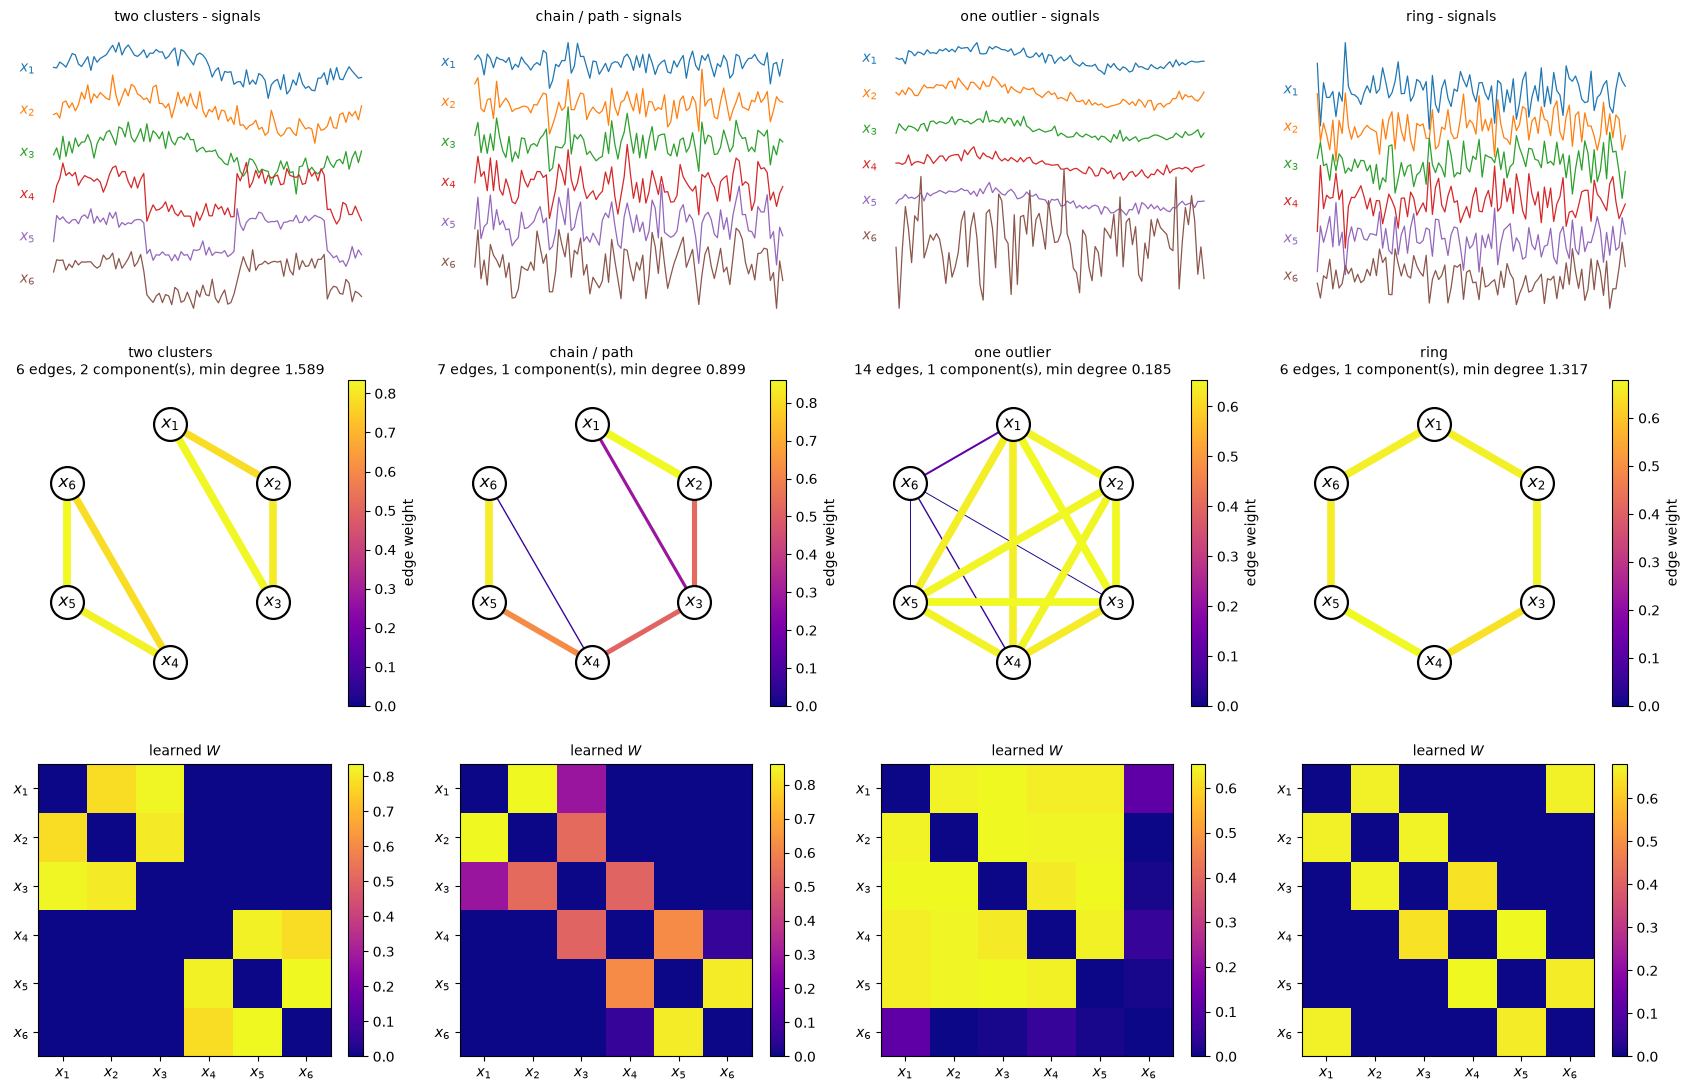

In [ ]:

ALPHA, BETA = 1.0, 0.5
S = S_op(M)
print(f"step size must satisfy  gamma < 1/(2*beta + ||S||) = "
      f"{1/(2*BETA + np.linalg.norm(S, 2)):.4f}\n")
print(f"{'toy':14s} {'iters':>6s} {'edges':>6s} {'comps':>6s} {'min deg':>9s}")

fig, axes = plt.subplots(3, 4, figsize=(17, 11), height_ratios=[1, 1.25, 1])
for c, (name, X) in enumerate(TOYS):

    # ---- the signals we feed in --------------------------------------------
    off = 2.6*np.std(X)
    for k in range(M):
        axes[0, c].plot(X[k, :100] - k*off, lw=0.9, color=plt.cm.tab10(k))
        axes[0, c].text(-6, -k*off, rf"$x_{{{k+1}}}$", ha="right", va="center",
                        fontsize=10, color=plt.cm.tab10(k))
    axes[0, c].set_title(f"{name} - signals", fontsize=10)
    axes[0, c].set_xticks([]); axes[0, c].set_yticks([]); axes[0, c].set_xlim(-14, 100)
    for sp in axes[0, c].spines.values():
        sp.set_visible(False)

    # ---- learn the graph ----------------------------------------------------
    z, i, j = Z_vec(X)
    z = z/z.mean()          # normalise: makes (alpha, beta) mean the same thing on every toy
    w, d, n_it = fbf_primal_dual(z, ALPHA, BETA, S)

    W     = vec_to_W(w, M)
    deg   = S @ w
    n_edg = int((w > 1e-6*w.max()).sum())
    ncomp, _ = connected_components((W > 1e-6*w.max()).astype(int), directed=False)
    print(f"{name:14s} {n_it:6d} {n_edg:6d} {ncomp:6d} {deg.min():9.4f}")

    # ---- the graph, edge colour + thickness = weight ------------------------
    lc = draw_graph(axes[1, c], w,
                    title=f"{name}\n{n_edg} edges, {ncomp} component(s), "
                          f"min degree {deg.min():.3f}")
    plt.colorbar(lc, ax=axes[1, c], fraction=0.046, label="edge weight")

    # ---- the same W as a matrix heatmap -------------------------------------
    im = axes[2, c].imshow(W, cmap="plasma")
    plt.colorbar(im, ax=axes[2, c], fraction=0.046)
    axes[2, c].set_xticks(range(M), [rf"$x_{{{k+1}}}$" for k in range(M)])
    axes[2, c].set_yticks(range(M), [rf"$x_{{{k+1}}}$" for k in range(M)])
    axes[2, c].set_title("learned $W$", fontsize=10)

plt.tight_layout()
plt.show()

